# Recetario de Data Cleaning 

Este notebook aplica, en código, **cada uno de los pasos** descritos en el documento *Recetario de Data Cleaning*:

1. Análisis Exploratorio de Datos (EDA)
2. Manejo de valores faltantes
3. Detección y manejo de outliers (IQR, Z-score, MAD, media recortada, 3σ)
4. Normalización / Estandarización
5. Codificación de variables categóricas
6. División del conjunto de datos
7. Validación cruzada

El notebook está dividido en dos partes:

- **Parte A — Dataset guía:** el mismo mini conjunto de datos de 10 personas usado en el documento (salario con un faltante y un outlier), extendido con edad, ciudad, nivel educativo y una variable objetivo, para poder recorrer el pipeline completo de principio a fin.
- **Parte B — Dataset sofisticado:** un dataset sintético de **riesgo crediticio** con 600 registros, varias columnas numéricas y categóricas, valores faltantes, outliers reales y una variable objetivo binaria (`default`), tratado con el mismo pipeline pero usando buenas prácticas de nivel producción (`Pipeline` + `ColumnTransformer` de scikit-learn, sin fuga de información).


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore, median_abs_deviation, trim_mean

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
np.random.seed(42)


# PARTE A — Dataset guía

Recreamos el mismo mini dataset del documento de Word: 10 personas con su salario mensual (en millones de pesos). Uno de los valores no fue reportado (`NaN`) y otro corresponde a un salario mucho más alto que el resto (outlier). Lo extendemos con `edad`, `ciudad`, `nivel_educativo` y una variable objetivo `compra` (1 = compró un producto financiero, 0 = no) para poder ilustrar también escalado, codificación, partición y validación cruzada.


In [8]:
guia = pd.DataFrame({
    'persona': [f'P{i}' for i in range(1, 11)],
    'salario': [2.1, 2.3, 2.0, 2.4, 2.2, np.nan, 2.5, 2.1, 15.8, 2.3],  # millones COP
    'edad': [25, 34, 29, 41, 38, 45, 30, 27, 52, 33],
    'ciudad': ['Bogota', 'Medellin', 'Cali', 'Bogota', 'Medellin',
               'Bogota', 'Cali', 'Medellin', 'Bogota', 'Cali'],
    'nivel_educativo': ['secundaria', 'universitario', 'primaria', 'universitario', 'secundaria',
                         'universitario', 'primaria', 'secundaria', 'universitario', 'secundaria'],
    'compra': [0, 1, 0, 1, 1, 1, 0, 0, 1, 0],
})
guia


,persona,salario,edad,ciudad,nivel_educativo,compra
0,P1,2.1,25,Bogota,secundaria,0
1,P2,2.3,34,Medellin,universitario,1
2,P3,2.0,29,Cali,primaria,0
3,P4,2.4,41,Bogota,universitario,1
4,P5,2.2,38,Medellin,secundaria,1
5,P6,NaN,45,Bogota,universitario,1
6,P7,2.5,30,Cali,primaria,0
7,P8,2.1,27,Medellin,secundaria,0
8,P9,15.8,52,Bogota,universitario,1
9,P10,2.3,33,Cali,secundaria,0


## A.1 — Análisis Exploratorio de Datos (EDA)

In [10]:
# Tipos de dato y conteo de no-nulos
guia.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   persona          10 non-null     object 
 1   salario          9 non-null      float64
 2   edad             10 non-null     int64  
 3   ciudad           10 non-null     object 
 4   nivel_educativo  10 non-null     object 
 5   compra           10 non-null     int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 612.0+ bytes


In [12]:
# Estadísticas descriptivas de las columnas numéricas
guia.describe()

,salario,edad,compra
count,9.000000,10.000000,10.000000
mean,3.744444,35.400000,0.500000
std,4.523580,8.579044,0.527046
min,2.000000,25.000000,0.000000
25%,2.100000,29.250000,0.000000
50%,2.300000,33.500000,0.500000
75%,2.400000,40.250000,1.000000
max,15.800000,52.000000,1.000000


In [14]:
# Media vs mediana: la gran diferencia ya delata un outlier en 'salario'
media = guia['salario'].mean()
mediana = guia['salario'].median()
print(f"Media del salario:   {media:.2f}")
print(f"Mediana del salario: {mediana:.2f}")
print(f"Diferencia:          {media - mediana:.2f}  <- señal de un outlier fuerte")

Media del salario:   3.74
Mediana del salario: 2.30
Diferencia:          1.44  <- señal de un outlier fuerte


In [16]:
# Porcentaje de valores faltantes por columna
guia.isna().mean().sort_values(ascending=False) * 100

salario            10.0
persona             0.0
edad                0.0
ciudad              0.0
nivel_educativo     0.0
compra              0.0
dtype: float64

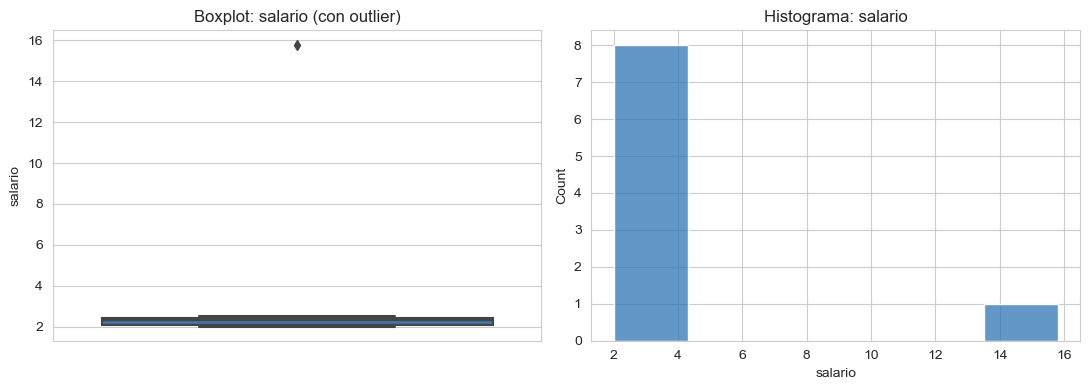

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(y=guia['salario'], ax=axes[0], color='#2E74B5')
axes[0].set_title('Boxplot: salario (con outlier)')

sns.histplot(guia['salario'].dropna(), bins=6, ax=axes[1], color='#2E74B5')
axes[1].set_title('Histograma: salario')

plt.tight_layout()
plt.show()

## A.2 — Manejo de valores faltantes

`P6` no reportó su salario. Como la columna tiene un outlier (`P9` = 15.8), imputar con la **media** sería engañoso — la inflaría hacia arriba. Usamos la **mediana**, más representativa del salario típico.


In [8]:
print("Faltantes en 'salario' antes de imputar:", guia['salario'].isna().sum())

# Opción A: eliminar filas con faltantes (referencia, no la usamos en el pipeline final)
guia_dropna = guia.dropna(subset=['salario'])
print("Filas si elimináramos en vez de imputar:", len(guia_dropna))

# Opción B (la que usamos): imputar con la mediana
mediana_salario = guia['salario'].median()
guia['salario'] = guia['salario'].fillna(mediana_salario)

print("Faltantes en 'salario' después de imputar:", guia['salario'].isna().sum())
guia


Faltantes en 'salario' antes de imputar: 1
Filas si elimináramos en vez de imputar: 9
Faltantes en 'salario' después de imputar: 0


,persona,salario,edad,ciudad,nivel_educativo,compra
0,P1,2.1,25,Bogota,secundaria,0
1,P2,2.3,34,Medellin,universitario,1
2,P3,2.0,29,Cali,primaria,0
3,P4,2.4,41,Bogota,universitario,1
4,P5,2.2,38,Medellin,secundaria,1
5,P6,2.3,45,Bogota,universitario,1
6,P7,2.5,30,Cali,primaria,0
7,P8,2.1,27,Medellin,secundaria,0
8,P9,15.8,52,Bogota,universitario,1
9,P10,2.3,33,Cali,secundaria,0


## A.3 — Detección y manejo de outliers

Aplicamos los métodos estadísticos clásicos del documento sobre `salario` y comparamos qué detecta cada uno.


In [9]:
salario = guia['salario']

# --- Método IQR ---
Q1 = salario.quantile(0.25)
Q3 = salario.quantile(0.75)
IQR = Q3 - Q1
lim_inf_iqr = Q1 - 1.5 * IQR
lim_sup_iqr = Q3 + 1.5 * IQR
outliers_iqr = guia[(salario < lim_inf_iqr) | (salario > lim_sup_iqr)]

print("=== Método IQR ===")
print(f"Q1={Q1:.2f}  Q3={Q3:.2f}  IQR={IQR:.2f}")
print(f"Límites: [{lim_inf_iqr:.2f}, {lim_sup_iqr:.2f}]")
print("Outliers detectados:\n", outliers_iqr[['persona', 'salario']])


=== Método IQR ===
Q1=2.12  Q3=2.38  IQR=0.25
Límites: [1.75, 2.75]
Outliers detectados:
   persona  salario
8      P9     15.8


In [10]:
# --- Método Z-score ---
z = zscore(salario)
guia['zscore'] = z
outliers_z = guia[(guia['zscore'] > 3) | (guia['zscore'] < -3)]

print("=== Método Z-score ===")
print(f"Media={salario.mean():.2f}  Desv. estándar={salario.std():.2f}")
print(guia[['persona', 'salario', 'zscore']])
print("\nOutliers detectados:", "ninguno" if outliers_iqr is not None and len(outliers_z) == 0 else list(outliers_z['persona']))
print("\n>>> El Z-score de P9 no supera 3 porque el propio outlier infla la desviación estándar.")
print(">>> Por eso el Z-score, a diferencia del IQR, NO detecta aquí el outlier.")


=== Método Z-score ===
Media=3.60  Desv. estándar=4.29
  persona  salario    zscore
0      P1      2.1 -0.368627
1      P2      2.3 -0.319477
2      P3      2.0 -0.393202
3      P4      2.4 -0.294902
4      P5      2.2 -0.344052
5      P6      2.3 -0.319477
6      P7      2.5 -0.270327
7      P8      2.1 -0.368627
8      P9     15.8  2.998167
9     P10      2.3 -0.319477

Outliers detectados: ninguno

>>> El Z-score de P9 no supera 3 porque el propio outlier infla la desviación estándar.
>>> Por eso el Z-score, a diferencia del IQR, NO detecta aquí el outlier.


In [11]:
# --- Método MAD (mediana + desviación absoluta mediana) ---
mediana_s = salario.median()
mad = median_abs_deviation(salario)
lim_inf_mad = mediana_s - 2.5 * mad
lim_sup_mad = mediana_s + 2.5 * mad
outliers_mad = guia[(salario < lim_inf_mad) | (salario > lim_sup_mad)]

print("=== Método MAD ===")
print(f"Mediana={mediana_s:.2f}  MAD={mad:.2f}")
print(f"Límites: [{lim_inf_mad:.2f}, {lim_sup_mad:.2f}]")
print("Outliers detectados:\n", outliers_mad[['persona', 'salario']])


=== Método MAD ===
Mediana=2.30  MAD=0.15
Límites: [1.93, 2.67]
Outliers detectados:
   persona  salario
8      P9     15.8


In [12]:
# --- Regla de los 3 sigma ---
mean_s, std_s = salario.mean(), salario.std()
lim_inf_3s = mean_s - 3 * std_s
lim_sup_3s = mean_s + 3 * std_s
outliers_3s = guia[(salario < lim_inf_3s) | (salario > lim_sup_3s)]

print("=== Regla de 3 sigma ===")
print(f"Límites: [{lim_inf_3s:.2f}, {lim_sup_3s:.2f}]")
print("Outliers detectados:\n", (outliers_3s[['persona', 'salario']] if len(outliers_3s) else "ninguno"))


=== Regla de 3 sigma ===
Límites: [-9.27, 16.47]
Outliers detectados:
 ninguno


In [13]:
# --- Media recortada (ejemplo con otro conjunto: notas de examen, como en el documento) ---
notas = pd.Series([55, 58, 60, 62, 63, 65, 67, 70, 72, 98])

media_simple = notas.mean()
media_recortada = trim_mean(notas, proportiontocut=0.1)
mediana_notas = notas.median()

print("=== Media recortada (10%) ===")
print(f"Media simple:     {media_simple:.2f}")
print(f"Media recortada:  {media_recortada:.2f}")
print(f"Mediana:          {mediana_notas:.2f}")


=== Media recortada (10%) ===
Media simple:     67.00
Media recortada:  64.62
Mediana:          64.00


In [14]:
# --- Resumen comparativo de detección ---
resumen = pd.DataFrame({
    'Método': ['IQR', 'Z-score', 'MAD', '3 sigma'],
    'Detecta a P9 (15.8) como outlier': [
        len(outliers_iqr) > 0,
        len(outliers_z) > 0,
        len(outliers_mad) > 0,
        len(outliers_3s) > 0,
    ]
})
resumen

,Método,Detecta a P9 (15.8) como outlier
0,IQR,True
1,Z-score,False
2,MAD,True
3,3 sigma,False


**Manejo del outlier:** dado que el salario de `P9` corresponde a un caso real (no un error de captura), en vez de eliminarlo usamos dos alternativas que preservan la fila: transformación logarítmica y *winsorizing* (recorte a los límites del IQR).


In [15]:
# Transformación logarítmica
guia['salario_log'] = np.log(guia['salario'])

# Winsorizing: recorta al límite del IQR en vez de eliminar
guia['salario_wz'] = guia['salario'].clip(lower=lim_inf_iqr, upper=lim_sup_iqr)

guia[['persona', 'salario', 'salario_log', 'salario_wz']]


,persona,salario,salario_log,salario_wz
0,P1,2.1,0.741937,2.10
1,P2,2.3,0.832909,2.30
2,P3,2.0,0.693147,2.00
3,P4,2.4,0.875469,2.40
4,P5,2.2,0.788457,2.20
5,P6,2.3,0.832909,2.30
6,P7,2.5,0.916291,2.50
7,P8,2.1,0.741937,2.10
8,P9,15.8,2.760010,2.75
9,P10,2.3,0.832909,2.30


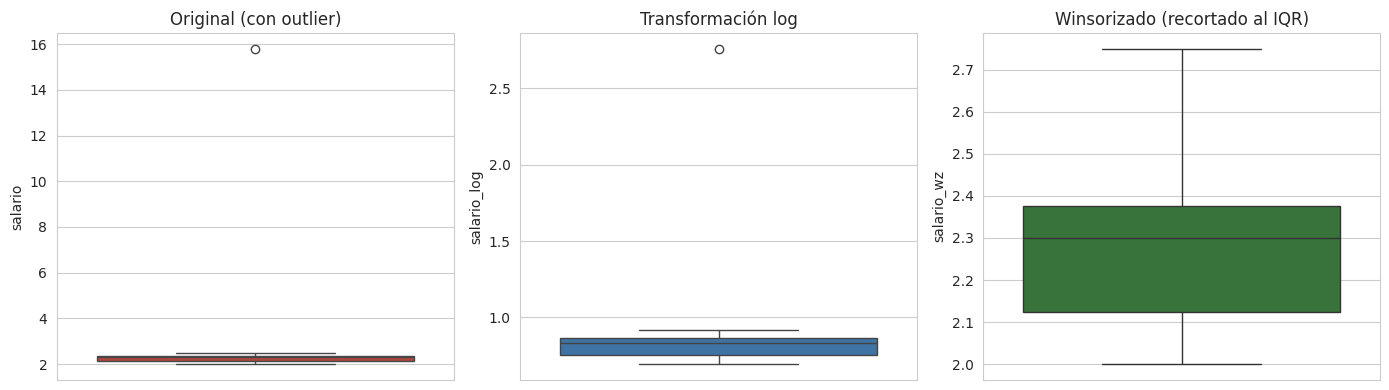

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=guia['salario'], ax=axes[0], color='#C0392B')
axes[0].set_title('Original (con outlier)')
sns.boxplot(y=guia['salario_log'], ax=axes[1], color='#2E74B5')
axes[1].set_title('Transformación log')
sns.boxplot(y=guia['salario_wz'], ax=axes[2], color='#2E7D32')
axes[2].set_title('Winsorizado (recortado al IQR)')
plt.tight_layout()
plt.show()


## A.4 — Normalización y estandarización

Usamos la versión *winsorizada* del salario (ya sin el efecto extremo del outlier) junto con la edad, para ilustrar ambas técnicas de escalado.


In [17]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

cols_numericas = ['salario_wz', 'edad']

# Estandarización (media 0, desviación estándar 1)
std_scaler = StandardScaler()
guia_std = guia.copy()
guia_std[cols_numericas] = std_scaler.fit_transform(guia[cols_numericas])

# Normalización (rango 0 a 1)
minmax_scaler = MinMaxScaler()
guia_norm = guia.copy()
guia_norm[cols_numericas] = minmax_scaler.fit_transform(guia[cols_numericas])

print("Estandarizado:")
display(guia_std[['persona'] + cols_numericas])
print("\nNormalizado:")
display(guia_norm[['persona'] + cols_numericas])


Estandarizado:


,persona,salario_wz,edad
0,P1,-0.937923,-1.277830
1,P2,0.024049,-0.172016
2,P3,-1.418909,-0.786357
3,P4,0.505035,0.688062
4,P5,-0.456937,0.319458
5,P6,0.024049,1.179536
6,P7,0.986021,-0.663489
7,P8,-0.937923,-1.032094
8,P9,2.188487,2.039614
9,P10,0.024049,-0.294884



Normalizado:


,persona,salario_wz,edad
0,P1,0.133333,0.000000
1,P2,0.400000,0.333333
2,P3,0.000000,0.148148
3,P4,0.533333,0.592593
4,P5,0.266667,0.481481
5,P6,0.400000,0.740741
6,P7,0.666667,0.185185
7,P8,0.133333,0.074074
8,P9,1.000000,1.000000
9,P10,0.400000,0.296296


## A.5 — Codificación de variables categóricas

- `ciudad` es **nominal** (sin orden) → One-Hot Encoding.
- `nivel_educativo` es **ordinal** (primaria < secundaria < universitario) → Label/Ordinal Encoding respetando ese orden.


In [18]:
# One-Hot Encoding para 'ciudad' (nominal)
guia_encoded = pd.get_dummies(guia, columns=['ciudad'], prefix='ciudad')

# Ordinal Encoding para 'nivel_educativo' (SÍ tiene orden natural)
orden_educativo = {'primaria': 0, 'secundaria': 1, 'universitario': 2}
guia_encoded['nivel_educativo_cod'] = guia['nivel_educativo'].map(orden_educativo)

guia_encoded[['persona', 'nivel_educativo', 'nivel_educativo_cod',
              'ciudad_Bogota', 'ciudad_Medellin', 'ciudad_Cali']]


,persona,nivel_educativo,nivel_educativo_cod,ciudad_Bogota,ciudad_Medellin,ciudad_Cali
0,P1,secundaria,1,True,False,False
1,P2,universitario,2,False,True,False
2,P3,primaria,0,False,False,True
3,P4,universitario,2,True,False,False
4,P5,secundaria,1,False,True,False
5,P6,universitario,2,True,False,False
6,P7,primaria,0,False,False,True
7,P8,secundaria,1,False,True,False
8,P9,universitario,2,True,False,False
9,P10,secundaria,1,False,False,True


## A.6 — División del conjunto de datos

Con solo 10 filas el split es meramente ilustrativo (en la Parte B se hace con un dataset de tamaño realista), pero el código es el mismo que usarías en un caso real.


In [19]:
from sklearn.model_selection import train_test_split

X = guia_encoded[['salario_wz', 'edad', 'nivel_educativo_cod',
                   'ciudad_Bogota', 'ciudad_Medellin', 'ciudad_Cali']]
y = guia_encoded['compra']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)


Entrenamiento: (8, 6)  Prueba: (2, 6)


## A.7 — Validación cruzada

Con un dataset tan pequeño, k-fold sirve sobre todo para ilustrar el mecanismo (aquí usamos `cv=4` porque solo hay 8 filas de entrenamiento).


In [20]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()
scores = cross_val_score(modelo, X_train, y_train, cv=4)

print("Puntuaciones de validación cruzada:", np.round(scores, 2))
print(f"Promedio: {scores.mean():.2f}  Desviación: {scores.std():.2f}")


Puntuaciones de validación cruzada: [1. 1. 1. 1.]
Promedio: 1.00  Desviación: 0.00


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


> Con un dataset de 10 filas estos resultados no son estadísticamente significativos — el objetivo aquí es puramente mostrar la mecánica del código. En la Parte B se repite exactamente el mismo pipeline sobre un dataset con tamaño y complejidad realistas.


---
# PARTE B — Dataset mucho más sofisticado: riesgo crediticio

Generamos un dataset sintético de **600 solicitantes de crédito**, con:

- Variables numéricas: `edad`, `ingreso_mensual`, `deuda_total`, `antiguedad_laboral_meses`, `score_crediticio`, `num_pagos_tardios`.
- Variables categóricas: `ciudad` (nominal), `nivel_educativo` (ordinal), `tipo_contrato` (nominal).
- Variable objetivo: `default` (1 = incumplió el crédito, 0 = pagó normalmente).
- Valores faltantes inyectados en `ingreso_mensual` y `antiguedad_laboral_meses` (más frecuentes en personas jóvenes, simulando un patrón **MAR**: la ausencia depende de otra variable observada).
- Outliers reales en `ingreso_mensual` y `deuda_total` (un pequeño grupo de ingresos muy altos).

Aplicamos el mismo pipeline de 7 pasos, esta vez con herramientas de nivel producción de scikit-learn (`ColumnTransformer` + `Pipeline`) para garantizar que **no haya fuga de información**: todo el preprocesamiento (imputación, escalado, codificación) se ajusta *solo* con el conjunto de entrenamiento.


In [21]:
# Generación del dataset sintético
rng = np.random.default_rng(7)
n = 600

edad = rng.integers(18, 70, size=n)
antiguedad_laboral_meses = np.clip(rng.normal(60, 40, size=n), 0, None).round(0)
score_crediticio = np.clip(rng.normal(650, 80, size=n), 300, 850).round(0)
num_pagos_tardios = rng.poisson(1.2, size=n)

# Ingreso mensual (COP, en millones) con cola larga a la derecha (log-normal) + un grupo de outliers reales
ingreso_mensual = rng.lognormal(mean=1.0, sigma=0.45, size=n)
idx_altos = rng.choice(n, size=12, replace=False)
ingreso_mensual[idx_altos] *= rng.uniform(6, 10, size=12)  # ingresos excepcionalmente altos (outliers reales)

deuda_total = np.clip(ingreso_mensual * rng.normal(3.5, 1.8, size=n), 0, None)
idx_deuda_alta = rng.choice(n, size=8, replace=False)
deuda_total[idx_deuda_alta] *= rng.uniform(4, 7, size=8)  # outliers de deuda

ciudad = rng.choice(
    ['Bogota', 'Medellin', 'Cali', 'Barranquilla', 'Cartagena'],
    size=n, p=[0.35, 0.22, 0.18, 0.15, 0.10]
)
nivel_educativo = rng.choice(
    ['primaria', 'secundaria', 'tecnico', 'universitario', 'posgrado'],
    size=n, p=[0.08, 0.30, 0.22, 0.30, 0.10]
)
tipo_contrato = rng.choice(
    ['indefinido', 'fijo', 'prestacion_servicios'],
    size=n, p=[0.45, 0.30, 0.25]
)

# Variable objetivo: probabilidad de default depende de score, deuda/ingreso y pagos tardíos
ratio_deuda_ingreso = deuda_total / (ingreso_mensual + 0.1)
logit = (
    -2
    + 0.35 * num_pagos_tardios
    + 0.9 * (ratio_deuda_ingreso > 4)
    - 0.006 * (score_crediticio - 650)
    + 0.6 * (tipo_contrato == 'prestacion_servicios')
)
prob_default = 1 / (1 + np.exp(-logit))
default = rng.binomial(1, prob_default)

credito = pd.DataFrame({
    'edad': edad,
    'ingreso_mensual': ingreso_mensual.round(2),
    'deuda_total': deuda_total.round(2),
    'antiguedad_laboral_meses': antiguedad_laboral_meses,
    'score_crediticio': score_crediticio,
    'num_pagos_tardios': num_pagos_tardios,
    'ciudad': ciudad,
    'nivel_educativo': nivel_educativo,
    'tipo_contrato': tipo_contrato,
    'default': default,
})

# Inyectar valores faltantes tipo MAR: más frecuentes en personas jóvenes
prob_faltante_ingreso = np.where(credito['edad'] < 28, 0.25, 0.05)
mask_ingreso = rng.random(n) < prob_faltante_ingreso
credito.loc[mask_ingreso, 'ingreso_mensual'] = np.nan

prob_faltante_antig = np.where(credito['edad'] < 28, 0.20, 0.04)
mask_antig = rng.random(n) < prob_faltante_antig
credito.loc[mask_antig, 'antiguedad_laboral_meses'] = np.nan

credito.head(10)


,edad,ingreso_mensual,deuda_total,antiguedad_laboral_meses,score_crediticio,num_pagos_tardios,ciudad,nivel_educativo,tipo_contrato,default
0,67,2.20,3.30,69.0,703.0,1,Barranquilla,tecnico,indefinido,0
1,50,1.96,3.65,50.0,564.0,1,Bogota,secundaria,indefinido,1
2,53,4.02,13.36,52.0,665.0,2,Medellin,secundaria,prestacion_servicios,0
3,64,4.24,11.59,62.0,565.0,3,Barranquilla,primaria,prestacion_servicios,1
4,48,4.24,29.75,120.0,741.0,0,Bogota,secundaria,indefinido,0
5,58,1.91,0.00,82.0,835.0,0,Medellin,primaria,indefinido,0
6,61,2.65,10.99,58.0,812.0,0,Medellin,secundaria,indefinido,1
7,29,4.32,20.67,37.0,632.0,0,Medellin,posgrado,prestacion_servicios,1
8,20,2.02,3.00,35.0,709.0,0,Medellin,secundaria,fijo,0
9,33,1.94,4.54,124.0,660.0,1,Cali,tecnico,prestacion_servicios,0


## B.1 — Análisis Exploratorio de Datos (EDA)

In [22]:
credito.info()


<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   edad                      600 non-null    int64  
 1   ingreso_mensual           549 non-null    float64
 2   deuda_total               600 non-null    float64
 3   antiguedad_laboral_meses  559 non-null    float64
 4   score_crediticio          600 non-null    float64
 5   num_pagos_tardios         600 non-null    int64  
 6   ciudad                    600 non-null    str    
 7   nivel_educativo           600 non-null    str    
 8   tipo_contrato             600 non-null    str    
 9   default                   600 non-null    int64  
dtypes: float64(4), int64(3), str(3)
memory usage: 47.0 KB


In [23]:
credito.describe()


,edad,ingreso_mensual,deuda_total,antiguedad_laboral_meses,score_crediticio,num_pagos_tardios,default
count,600.000000,549.000000,600.000000,559.000000,600.000000,600.0000,600.000000
mean,44.326667,3.403552,12.767483,57.533095,650.256667,1.2150,0.258333
std,15.042509,3.036107,16.188419,36.066822,82.536140,1.1609,0.438083
min,18.000000,0.800000,0.000000,0.000000,428.000000,0.0000,0.000000
25%,31.000000,2.020000,5.355000,30.000000,593.000000,0.0000,0.000000
50%,45.000000,2.780000,9.345000,56.000000,647.000000,1.0000,0.000000
75%,57.000000,3.790000,15.272500,81.500000,708.250000,2.0000,1.000000
max,69.000000,40.330000,234.640000,163.000000,850.000000,6.0000,1.000000


In [24]:
# Porcentaje de faltantes por columna
(credito.isna().mean() * 100).sort_values(ascending=False)


ingreso_mensual             8.500000
antiguedad_laboral_meses    6.833333
edad                        0.000000
deuda_total                 0.000000
score_crediticio            0.000000
num_pagos_tardios           0.000000
ciudad                      0.000000
nivel_educativo             0.000000
tipo_contrato               0.000000
default                     0.000000
dtype: float64

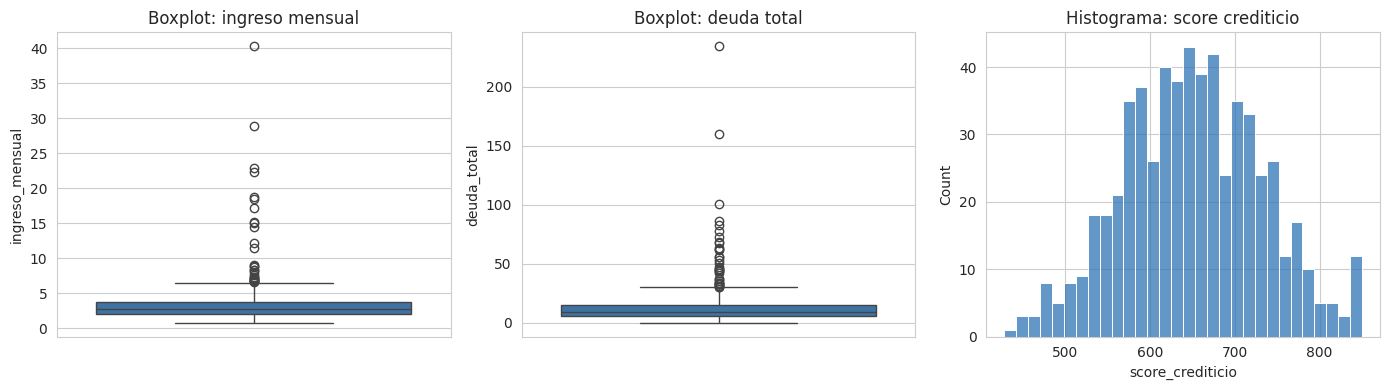

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=credito['ingreso_mensual'], ax=axes[0], color='#2E74B5')
axes[0].set_title('Boxplot: ingreso mensual')
sns.boxplot(y=credito['deuda_total'], ax=axes[1], color='#2E74B5')
axes[1].set_title('Boxplot: deuda total')
sns.histplot(credito['score_crediticio'], bins=30, ax=axes[2], color='#2E74B5')
axes[2].set_title('Histograma: score crediticio')
plt.tight_layout()
plt.show()


In [26]:
# Relación entre faltantes de ingreso y edad: confirma el patrón MAR que inyectamos
credito.assign(ingreso_faltante=credito['ingreso_mensual'].isna()).groupby('ingreso_faltante')['edad'].mean()


ingreso_faltante
False    45.065574
True     36.372549
Name: edad, dtype: float64

## B.2 — Manejo de valores faltantes (con criterio, no automático)

Confirmamos visualmente que la ausencia de `ingreso_mensual` está relacionada con la edad (MAR) — por eso una imputación simple con la mediana es razonable como primer paso, pero documentamos la relación con `edad` que sí importa para el modelo. Definimos la estrategia de imputación aquí, pero **el ajuste (fit) se hará más abajo solo con el conjunto de entrenamiento**, dentro del pipeline.


In [27]:
print(f"Ingreso: {credito['ingreso_mensual'].isna().sum()} faltantes de {len(credito)} filas "
      f"({credito['ingreso_mensual'].isna().mean()*100:.1f}%)")
print(f"Antigüedad laboral: {credito['antiguedad_laboral_meses'].isna().sum()} faltantes "
      f"({credito['antiguedad_laboral_meses'].isna().mean()*100:.1f}%)")
print("\n>>> Ambas proporciones son manejables (<30%) y con relación conocida a 'edad'.")
print(">>> Estrategia: imputación por mediana dentro del pipeline (ajustada solo con train).")


Ingreso: 51 faltantes de 600 filas (8.5%)
Antigüedad laboral: 41 faltantes (6.8%)

>>> Ambas proporciones son manejables (<30%) y con relación conocida a 'edad'.
>>> Estrategia: imputación por mediana dentro del pipeline (ajustada solo con train).


## B.3 — Detección y manejo de outliers

Aplicamos IQR (robusto) sobre `ingreso_mensual` y `deuda_total`, y comparamos con Z-score para reforzar, en un dataset más grande, la misma lección de la Parte A.


In [28]:
def resumen_outliers_iqr(serie, nombre):
    s = serie.dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outliers = s[(s < lim_inf) | (s > lim_sup)]
    print(f"--- {nombre} ---")
    print(f"Límites IQR: [{lim_inf:.2f}, {lim_sup:.2f}]  ->  {len(outliers)} outliers "
          f"({len(outliers)/len(s)*100:.1f}% de los datos no nulos)")
    return lim_inf, lim_sup

lim_inf_ingreso, lim_sup_ingreso = resumen_outliers_iqr(credito['ingreso_mensual'], 'Ingreso mensual')
lim_inf_deuda, lim_sup_deuda = resumen_outliers_iqr(credito['deuda_total'], 'Deuda total')


--- Ingreso mensual ---
Límites IQR: [-0.64, 6.45]  ->  29 outliers (5.3% de los datos no nulos)
--- Deuda total ---
Límites IQR: [-9.52, 30.15]  ->  35 outliers (5.8% de los datos no nulos)


In [29]:
# Comparación con Z-score sobre 'ingreso_mensual'
ingreso_no_na = credito['ingreso_mensual'].dropna()
z_ingreso = zscore(ingreso_no_na)
outliers_z_ingreso = ingreso_no_na[(z_ingreso > 3) | (z_ingreso < -3)]

Q1, Q3 = ingreso_no_na.quantile(0.25), ingreso_no_na.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr_ingreso = ingreso_no_na[(ingreso_no_na < Q1 - 1.5*IQR) | (ingreso_no_na > Q3 + 1.5*IQR)]

print(f"Outliers detectados por IQR:     {len(outliers_iqr_ingreso)}")
print(f"Outliers detectados por Z-score: {len(outliers_z_ingreso)}")
print("\n>>> Con muchos más datos el Z-score ya no se 'esconde' tanto como en la Parte A,")
print(">>> pero el IQR sigue siendo más conservador y estable frente a la cola larga del ingreso.")


Outliers detectados por IQR:     29
Outliers detectados por Z-score: 10

>>> Con muchos más datos el Z-score ya no se 'esconde' tanto como en la Parte A,
>>> pero el IQR sigue siendo más conservador y estable frente a la cola larga del ingreso.


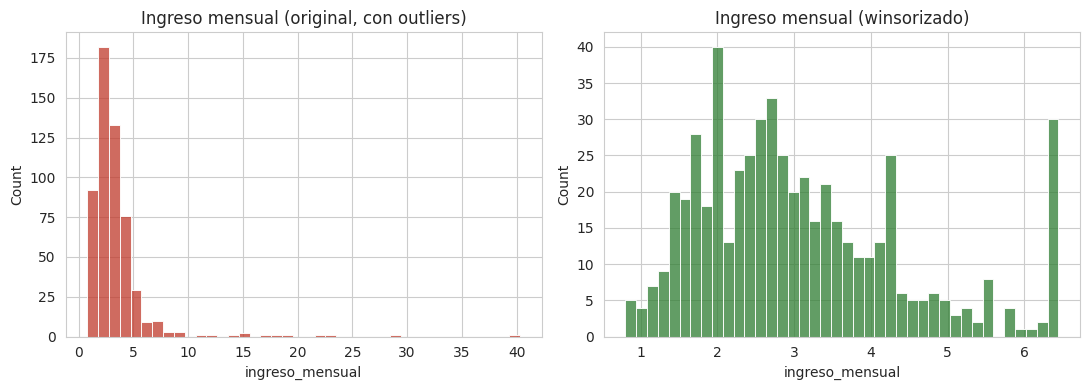

In [30]:
# Manejo: como los ingresos altos son datos reales (no errores), usamos winsorizing
# (recorte a los límites del IQR) en vez de eliminar filas -> se aplicará DENTRO del pipeline
# para no filtrar información del conjunto de prueba al de entrenamiento.

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(credito['ingreso_mensual'].dropna(), bins=40, ax=axes[0], color='#C0392B')
axes[0].set_title('Ingreso mensual (original, con outliers)')

ingreso_winsorizado = credito['ingreso_mensual'].clip(lower=lim_inf_ingreso, upper=lim_sup_ingreso)
sns.histplot(ingreso_winsorizado.dropna(), bins=40, ax=axes[1], color='#2E7D32')
axes[1].set_title('Ingreso mensual (winsorizado)')
plt.tight_layout()
plt.show()


## B.4 a B.7 — Pipeline completo sin fuga de información

A partir de aquí construimos un `Pipeline` de scikit-learn que encadena, **ajustándose solo con el conjunto de entrenamiento**:

1. Un transformador personalizado de *winsorizing* para las columnas con outliers.
2. Imputación de faltantes (mediana para numéricas).
3. Escalado (`StandardScaler`) para las variables numéricas.
4. Codificación: `OneHotEncoder` para nominales (`ciudad`, `tipo_contrato`) y `OrdinalEncoder` con orden explícito para `nivel_educativo`.
5. Un modelo de clasificación (`LogisticRegression`, con `class_weight='balanced'` porque `default` es una clase minoritaria) para predecir `default`.

Esto respeta la "regla de oro" del documento: dividir primero, y ajustar (`fit`) cualquier transformación solo con entrenamiento.


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# --- B.6: división del dataset (ANTES de ajustar cualquier transformación) ---
X = credito.drop(columns='default')
y = credito['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("Proporción de default en train:", y_train.mean().round(3),
      " en test:", y_test.mean().round(3))


Entrenamiento: (480, 9)  Prueba: (120, 9)
Proporción de default en train: 0.258  en test: 0.258


In [32]:
# --- B.3 (continuación): winsorizing como transformador reutilizable dentro del pipeline ---
cols_con_outliers = ['ingreso_mensual', 'deuda_total']

def winsorizar(X, limites):
    X = X.copy()
    for col, (lo, hi) in limites.items():
        X[col] = X[col].clip(lower=lo, upper=hi)
    return X

# Los límites se calculan SOLO con el set de entrenamiento (evita fuga de información)
limites_train = {}
for col in cols_con_outliers:
    s = X_train[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    limites_train[col] = (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Límites de winsorizing (calculados solo con train):")
for col, (lo, hi) in limites_train.items():
    print(f"  {col}: [{lo:.2f}, {hi:.2f}]")

winsorizer = FunctionTransformer(winsorizar, kw_args={'limites': limites_train})


Límites de winsorizing (calculados solo con train):
  ingreso_mensual: [-0.57, 6.33]
  deuda_total: [-9.74, 30.03]


In [33]:
# --- B.4 y B.5: columnas numéricas (imputar mediana + escalar) y categóricas (codificar) ---
cols_numericas = ['edad', 'ingreso_mensual', 'deuda_total',
                   'antiguedad_laboral_meses', 'score_crediticio', 'num_pagos_tardios']
cols_nominales = ['ciudad', 'tipo_contrato']
col_ordinal = ['nivel_educativo']
orden_educativo = [['primaria', 'secundaria', 'tecnico', 'universitario', 'posgrado']]

pipeline_numerico = Pipeline(steps=[
    ('imputar_mediana', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler()),
])

pipeline_ordinal = Pipeline(steps=[
    ('imputar_moda', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=orden_educativo)),
])

preprocesador = ColumnTransformer(transformers=[
    ('num', pipeline_numerico, cols_numericas),
    ('nom', OneHotEncoder(handle_unknown='ignore'), cols_nominales),
    ('ord', pipeline_ordinal, col_ordinal),
])

pipeline_completo = Pipeline(steps=[
    ('winsorizar', winsorizer),          # 3. tratar outliers
    ('preprocesar', preprocesador),      # 2. faltantes + 4. escalado + 5. codificación
    ('modelo', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

pipeline_completo


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('winsorizar', ...), ('preprocesar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function win...x7fa685d3b7e0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments

## B.7 — Validación cruzada y evaluación final

In [34]:
# Validación cruzada sobre el conjunto de entrenamiento (5-fold estratificado)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline_completo, X_train, y_train, cv=cv, scoring='roc_auc')

print("AUC por fold:", np.round(scores, 3))
print(f"AUC promedio: {scores.mean():.3f}  (desviación: {scores.std():.3f})")


AUC por fold: [0.606 0.387 0.644 0.674 0.629]
AUC promedio: 0.588  (desviación: 0.103)


In [35]:
# Entrenamiento final y evaluación en el conjunto de prueba (nunca visto durante el ajuste)
pipeline_completo.fit(X_train, y_train)
y_pred = pipeline_completo.predict(X_test)
y_proba = pipeline_completo.predict_proba(X_test)[:, 1]

print(f"Accuracy en test: {accuracy_score(y_test, y_pred):.3f}")
print(f"AUC en test:      {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=['no_default', 'default']))


Accuracy en test: 0.600
AUC en test:      0.646

              precision    recall  f1-score   support

  no_default       0.81      0.61      0.69        89
     default       0.34      0.58      0.43        31

    accuracy                           0.60       120
   macro avg       0.57      0.59      0.56       120
weighted avg       0.69      0.60      0.62       120

